In [3]:
import os, time, random, json, math
import numpy as np, pandas as pd
import torch, torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt
import torchvision
import torchvision.transforms.functional as TF
from torchvision.transforms import InterpolationMode
from sklearn.metrics import confusion_matrix

device = 'cuda' if torch.cuda.is_available() else 'cpu'
DATA_SEED, SHIFT_SEED, TRAIN_SEEDS = 0, 1234, [0, 1, 2]
MAX_EPOCHS = 60
CLASSES = ['airplane','automobile','bird','cat','deer','dog','frog','horse','ship','truck']

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
    torch.backends.cudnn.deterministic = True; torch.backends.cudnn.benchmark = False

set_seed(DATA_SEED)
print('device:', device, '| torch', torch.__version__)

device: cuda | torch 2.11.0+cu130


## 1. Data: `train_small`, validation split, `clean_test`

In [4]:
# Load CIFAR-10 datasets and define conversion helper
tr_set = torchvision.datasets.CIFAR10(root='./data', train=True, download=True)
te_set = torchvision.datasets.CIFAR10(root='./data', train=False, download=True)

def to_tensor(x):
    # convert numpy uint8 array to float32 tensor scaled to [0, 1]
    return torch.tensor(x).permute(0, 3, 1, 2).float() / 255.0

y_all = np.array(tr_set.targets)

# First construct train_small: exactly 50 randomly selected images per class.
rng = np.random.RandomState(DATA_SEED)
small_idx = []
for class_id in range(10):
    class_idx = np.where(y_all == class_id)[0]
    small_idx.extend(rng.choice(class_idx, 50, replace=False))
small_idx = np.array(small_idx)
train_small_images = tr_set.data[small_idx]
train_small_labels = y_all[small_idx]

# Split train_small into 400 training and 100 validation images (40/10 per class).
train_local_idx, val_local_idx = [], []
for class_id in range(10):
    class_positions = np.where(train_small_labels == class_id)[0]
    train_local_idx.extend(class_positions[:40])
    val_local_idx.extend(class_positions[40:50])
train_local_idx = np.array(train_local_idx)
val_local_idx = np.array(val_local_idx)

X_tr = to_tensor(train_small_images[train_local_idx])
y_tr = torch.tensor(train_small_labels[train_local_idx])
X_va = to_tensor(train_small_images[val_local_idx])
y_va = torch.tensor(train_small_labels[val_local_idx])
X_clean, y_test = to_tensor(te_set.data), torch.tensor(te_set.targets)

assert len(small_idx) == 500
assert np.bincount(train_small_labels, minlength=10).tolist() == [50] * 10
assert len(X_tr) == 400 and len(X_va) == 100
assert np.bincount(y_tr.numpy(), minlength=10).tolist() == [40] * 10
assert np.bincount(y_va.numpy(), minlength=10).tolist() == [10] * 10
assert not set(small_idx[train_local_idx]) & set(small_idx[val_local_idx])

print('train_small:', tuple(train_small_images.shape), '| 50 images per class')
print('train:', tuple(X_tr.shape), '| val:', tuple(X_va.shape), '| clean_test:', tuple(X_clean.shape))
print('train per class:', np.bincount(y_tr.numpy()), '| val per class:', np.bincount(y_va.numpy()))
X_tr_d, y_tr_d, X_va_d, y_va_d = X_tr.to(device), y_tr.to(device), X_va.to(device), y_va.to(device)

100%|██████████| 170M/170M [39:50<00:00, 71.3kB/s]


train_small: (500, 32, 32, 3) | 50 images per class
train: (400, 3, 32, 32) | val: (100, 3, 32, 32) | clean_test: (10000, 3, 32, 32)
train per class: [40 40 40 40 40 40 40 40 40 40] | val per class: [10 10 10 10 10 10 10 10 10 10]


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

## 2. Build `shifted_test` with a fixed seed

The visible assignment description mentions rotation (±25°), brightness/contrast changes, blur, noise, rectangular occlusion (about 25%), and one additional hidden corruption. The supplied follow-up clarifies rotation, brightness/contrast, occlusion, and the extra hidden corruption.

**Important:** the exact hidden corruption was not included in the materials available with this notebook. The code below uses random grayscale only as a clearly labelled temporary stand-in. Replace `hidden_corruption()` with the instructor's exact implementation when it is provided; otherwise Part E's hidden-corruption result cannot be claimed as the official result. The visible pipeline also adds blur and noise because they are explicitly mentioned in the assignment brief. The same fixed seed makes the generated test corruption reproducible.

built in 9.1s | shifted_test: (10000, 3, 32, 32)


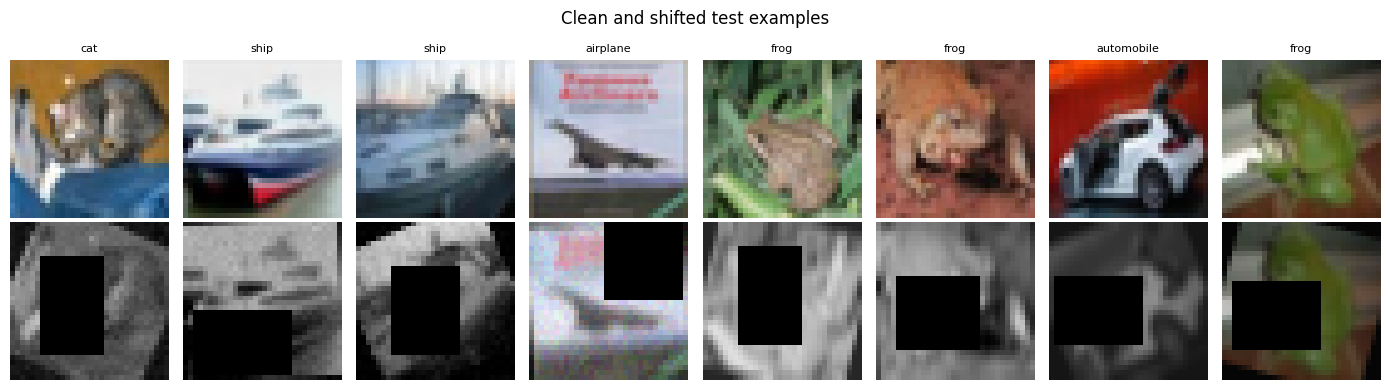

In [5]:
# Temporary stand-in only: replace this function when the official hidden corruption is provided.
def hidden_corruption(img, g):
    # Assumption for local testing only; NOT confirmed as the official hidden corruption.
    if torch.rand(1, generator=g).item() < 0.5:
        gray = (0.299 * img[0] + 0.587 * img[1] + 0.114 * img[2]).unsqueeze(0)
        return gray.expand(3, -1, -1).clone(), 1
    return img, 0

def add_gaussian_noise(img, g, std=0.03):
    noise = torch.randn(img.shape, generator=g) * std
    return (img + noise).clamp(0, 1)

def make_shifted(X, seed, listed=True, hidden=True):
    # All random choices use the local generator so the pipeline is reproducible.
    g = torch.Generator().manual_seed(seed)
    out, meta = [], []
    for img in X:
        img = img.clone()
        m = dict(angle=0., bright=1., contrast=1., occ=(0, 0, 0, 0),
                 blur=0, noise=0, gray=0)
        if listed:
            m['angle'] = (torch.rand(1, generator=g).item() * 2 - 1) * 25
            img = TF.rotate(img, m['angle'], interpolation=InterpolationMode.BILINEAR)

            m['bright'] = 0.5 + torch.rand(1, generator=g).item()
            m['contrast'] = 0.5 + torch.rand(1, generator=g).item()
            img = TF.adjust_contrast(
                TF.adjust_brightness(img, m['bright']), m['contrast']
            ).clamp(0, 1)

            # Blur and noise are listed in the original assignment description.
            if torch.rand(1, generator=g).item() < 0.3:
                img = TF.gaussian_blur(img, kernel_size=[3, 3], sigma=[0.1, 1.5])
                m['blur'] = 1
            if torch.rand(1, generator=g).item() < 0.3:
                img = add_gaussian_noise(img, g)
                m['noise'] = 1

            # Rectangle covers approximately 25% of the 32 x 32 image.
            area = 0.25 * 32 * 32
            ratio = math.exp((torch.rand(1, generator=g).item() * 2 - 1) * math.log(2))
            h = int(min(32, max(8, round(math.sqrt(area * ratio)))))
            w = int(min(32, round(area / h)))
            y0 = int(torch.randint(0, 32 - h + 1, (1,), generator=g))
            x0 = int(torch.randint(0, 32 - w + 1, (1,), generator=g))
            img[:, y0:y0 + h, x0:x0 + w] = 0.
            m['occ'] = (y0, x0, h, w)

        if hidden:
            img, m['gray'] = hidden_corruption(img, g)
        out.append(img.clamp(0, 1))
        meta.append(m)
    return torch.stack(out), meta

t0 = time.time()
X_shift, shift_meta = make_shifted(X_clean, SHIFT_SEED)
X_hidden, _ = make_shifted(X_clean, SHIFT_SEED + 1, listed=False, hidden=True)
print('built in %.1fs' % (time.time() - t0), '| shifted_test:', tuple(X_shift.shape))

fig, ax = plt.subplots(2, 8, figsize=(14, 4))
for i in range(8):
    ax[0, i].imshow(X_clean[i].permute(1, 2, 0)); ax[0, i].axis('off')
    ax[0, i].set_title(CLASSES[y_test[i]], fontsize=8)
    ax[1, i].imshow(X_shift[i].permute(1, 2, 0)); ax[1, i].axis('off')
ax[0, 0].set_ylabel('Clean', fontsize=9)
ax[1, 0].set_ylabel('Shifted', fontsize=9)
fig.suptitle('Clean and shifted test examples')
plt.tight_layout()
plt.show()

## 3. Augmentation toolbox (on the fly, training batches only)

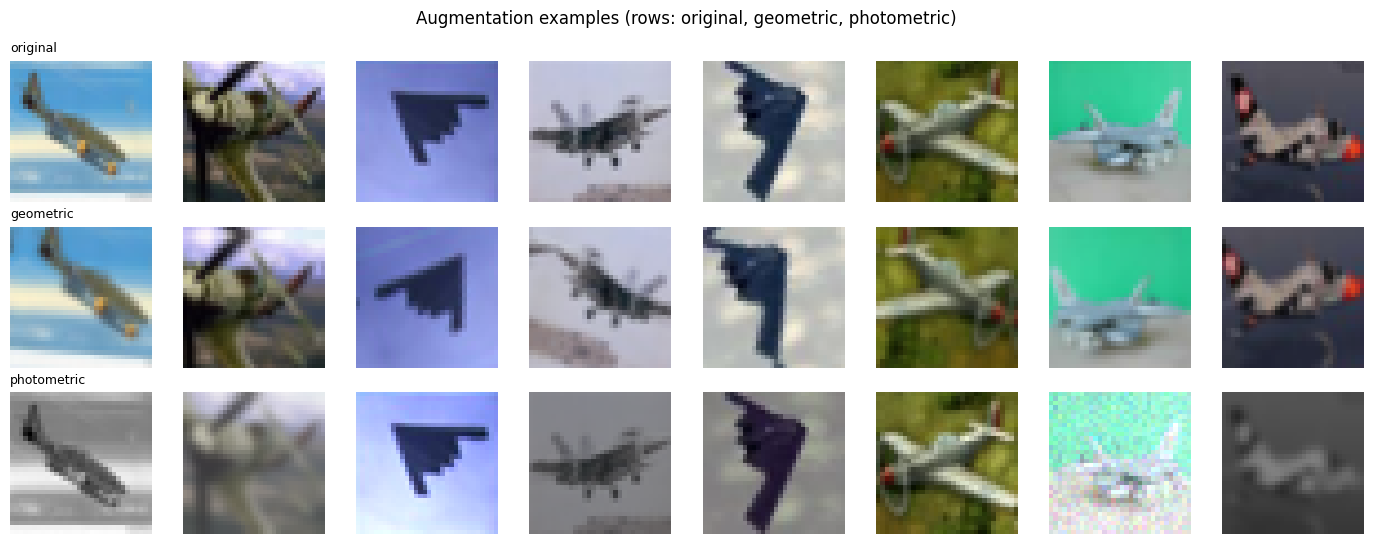

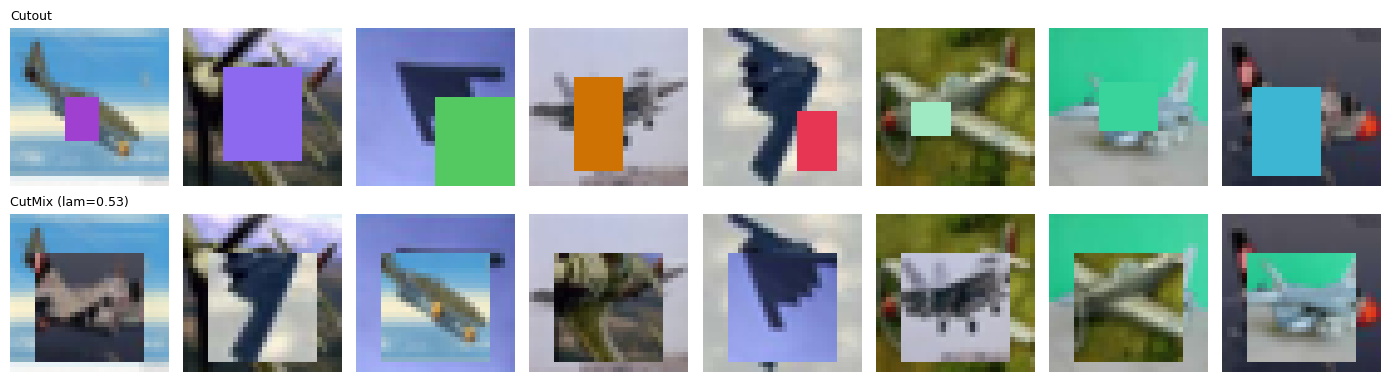

In [6]:
def geometric(x, rot=20., shift=0.125, scale=(0.9, 1.1), flip=True):
    B = x.size(0); d = x.device
    a = (torch.rand(B, device=d) * 2 - 1) * rot * math.pi / 180
    s = scale[0] + torch.rand(B, device=d) * (scale[1] - scale[0])
    tx, ty = [(torch.rand(B, device=d) * 2 - 1) * shift * 2 for _ in range(2)]
    fl = torch.where(torch.rand(B, device=d) < 0.5, -1., 1.) if flip else torch.ones(B, device=d)
    cos, sin = torch.cos(a) / s, torch.sin(a) / s
    theta = torch.stack([torch.stack([cos * fl, -sin, tx], 1), torch.stack([sin * fl, cos, ty], 1)], 1)
    grid = F.affine_grid(theta, x.shape, align_corners=False)
    return F.grid_sample(x, grid, padding_mode='reflection', align_corners=False)

def _gray(x): return (0.299 * x[:, 0:1] + 0.587 * x[:, 1:2] + 0.114 * x[:, 2:3])

def photometric(x, bright=0.5, contrast=0.5, sat=0.5, p_gray=0.25, p_shuffle=0.2, p_blur=0.3, p_noise=0.3, noise=0.05):
    B, C, H, W = x.shape; d = x.device
    r = lambda: torch.rand(B, 1, 1, 1, device=d) * 2 - 1
    x = x * (1 + r() * bright)
    m = x.mean((1, 2, 3), keepdim=True); x = (x - m) * (1 + r() * contrast) + m
    g = _gray(x); x = (x - g) * (1 + r() * sat) + g
    x = torch.where(torch.rand(B, 1, 1, 1, device=d) < p_gray, _gray(x).expand(-1, 3, -1, -1), x)     # colour-robustness
    idx = torch.argsort(torch.rand(B, 3, device=d), 1)                                                 # random channel permutation
    xs = torch.gather(x, 1, idx[:, :, None, None].expand(-1, -1, H, W))
    x = torch.where(torch.rand(B, 1, 1, 1, device=d) < p_shuffle, xs, x)
    sig = 0.5 + torch.rand(1).item() * 0.8
    k = torch.exp(-torch.arange(-2, 3, device=d).float() ** 2 / (2 * sig ** 2)); k = k / k.sum()
    xb = F.conv2d(F.pad(x, (2, 2, 0, 0), mode='reflect'), k.view(1, 1, 1, 5).repeat(3, 1, 1, 1), groups=3)
    xb = F.conv2d(F.pad(xb, (0, 0, 2, 2), mode='reflect'), k.view(1, 1, 5, 1).repeat(3, 1, 1, 1), groups=3)
    x = torch.where(torch.rand(B, 1, 1, 1, device=d) < p_blur, xb, x)
    x = x + (torch.rand(B, 1, 1, 1, device=d) < p_noise).float() * torch.randn_like(x) * noise
    return x.clamp(0, 1)

def _box_mask(B, H, W, area_lo, area_hi, d):
    area = (area_lo + torch.rand(B, device=d) * (area_hi - area_lo)) * H * W
    ar = torch.exp((torch.rand(B, device=d) * 2 - 1) * math.log(2))
    h = torch.sqrt(area * ar).clamp(4, H); w = (area / h).clamp(4, W)
    y0 = torch.rand(B, device=d) * (H - h); x0 = torch.rand(B, device=d) * (W - w)
    yy = torch.arange(H, device=d).view(1, H, 1).float(); xx = torch.arange(W, device=d).view(1, 1, W).float()
    return ((yy >= y0.view(B, 1, 1)) & (yy < (y0 + h).view(B, 1, 1)) & (xx >= x0.view(B, 1, 1)) & (xx < (x0 + w).view(B, 1, 1))).unsqueeze(1)

def cutout(x, p=0.6, area=(0.05, 0.30)):
    B, C, H, W = x.shape; d = x.device
    mask = _box_mask(B, H, W, area[0], area[1], d) & (torch.rand(B, 1, 1, 1, device=d) < p)
    return torch.where(mask, torch.rand(B, 3, 1, 1, device=d), x)       # random flat colour fill

def cutmix(x, y, alpha=1.0):
    B, C, H, W = x.shape
    lam = float(np.random.beta(alpha, alpha)); perm = torch.randperm(B, device=x.device)
    ch, cw = int(H * math.sqrt(1 - lam)), int(W * math.sqrt(1 - lam))
    cy, cx = np.random.randint(H), np.random.randint(W)
    y0, y1, x0, x1 = max(cy - ch // 2, 0), min(cy + ch // 2, H), max(cx - cw // 2, 0), min(cx + cw // 2, W)
    x = x.clone(); x[:, :, y0:y1, x0:x1] = x[perm][:, :, y0:y1, x0:x1]
    lam = 1 - (y1 - y0) * (x1 - x0) / (H * W)
    return x, y, y[perm], lam

def apply_aug(x, y, cfg):
    if cfg['geo']:    x = geometric(x)
    if cfg['photo']:  x = photometric(x)
    if cfg['cutout']: x = cutout(x)
    ya, yb, lam = y, y, 1.0
    if cfg['mix'] and np.random.rand() < cfg['mix_p']: x, ya, yb, lam = cutmix(x, y)
    return x, ya, yb, lam

set_seed(0)
b = X_tr_d[:8]
full = dict(geo=1, photo=1, cutout=1, mix=0, mix_p=0, ls=0.)
fig, ax = plt.subplots(3, 8, figsize=(14, 5.5))
for r_, (name, fn) in enumerate([('original', lambda z: z), ('geometric', geometric), ('photometric', photometric)]):
    o = fn(b)
    for i in range(8): ax[r_, i].imshow(o[i].permute(1, 2, 0).cpu().clamp(0, 1)); ax[r_, i].axis('off')
    ax[r_, 0].set_title(name, fontsize=9, loc='left')
fig.suptitle('Augmentation examples (rows: original, geometric, photometric)'); plt.tight_layout(); plt.show()
fig, ax = plt.subplots(2, 8, figsize=(14, 4))
co = cutout(b, p=1.0); cm_, _, _, lam = cutmix(b, y_tr_d[:8])
for i in range(8):
    ax[0, i].imshow(co[i].permute(1, 2, 0).cpu()); ax[0, i].axis('off')
    ax[1, i].imshow(cm_[i].permute(1, 2, 0).cpu()); ax[1, i].axis('off')
ax[0, 0].set_title('Cutout', fontsize=9, loc='left'); ax[1, 0].set_title('CutMix (lam=%.2f)' % lam, fontsize=9, loc='left')
plt.tight_layout(); plt.show()

## 4. Model: small Inception network (≤ 1M parameters)
LeNet-style front (3×3 conv + BN) → 3 Inception modules (parallel 1×1, 1×1→3×3, 1×1→5×5 and pool→1×1 branches, with 1×1 reductions) separated by max pooling → **global average pooling** → FC → **Dropout** → FC(10).

Placement of each regulariser is justified in Part C below.

In [7]:
def cbr(i, o, k, p=0):
    return nn.Sequential(nn.Conv2d(i, o, k, padding=p, bias=False), nn.BatchNorm2d(o), nn.ReLU(inplace=True))

class Inception(nn.Module):
    def __init__(self, i, c1, c3r, c3, c5r, c5, pp):
        super().__init__()
        self.b1 = cbr(i, c1, 1)
        self.b3 = nn.Sequential(cbr(i, c3r, 1), cbr(c3r, c3, 3, 1))
        self.b5 = nn.Sequential(cbr(i, c5r, 1), cbr(c5r, c5, 5, 2))
        self.bp = nn.Sequential(nn.MaxPool2d(3, 1, 1), cbr(i, pp, 1))
        self.out_ch = c1 + c3 + c5 + pp
    def forward(self, x): return torch.cat([self.b1(x), self.b3(x), self.b5(x), self.bp(x)], 1)

class InceptionNet(nn.Module):
    def __init__(self, drop=0.5):
        super().__init__()
        self.register_buffer('mean', torch.tensor([0.4914, 0.4822, 0.4465]).view(1, 3, 1, 1))
        self.register_buffer('std', torch.tensor([0.2470, 0.2435, 0.2616]).view(1, 3, 1, 1))
        self.stem = cbr(3, 32, 3, 1)
        self.a = Inception(32, 16, 16, 24, 8, 12, 12)       # -> 64 ch
        self.b = Inception(64, 32, 24, 48, 8, 16, 16)       # -> 112 ch
        self.c = Inception(112, 48, 32, 64, 12, 24, 24)     # -> 160 ch
        self.pool = nn.MaxPool2d(2)
        self.fc1 = nn.Linear(160, 64); self.drop = nn.Dropout(drop); self.fc2 = nn.Linear(64, 10)
    def forward(self, x):
        x = (x - self.mean) / self.std
        x = self.pool(self.a(self.stem(x)))      # 32 -> 16
        x = self.pool(self.b(x))                 # 16 -> 8
        x = self.c(x)
        x = x.mean((2, 3))                       # global average pooling
        return self.fc2(self.drop(F.relu(self.fc1(x))))

n_params = sum(p.numel() for p in InceptionNet().parameters() if p.requires_grad)
print('trainable parameters:', f'{n_params:,}'); assert n_params <= 1_000_000

trainable parameters: 77,586


## 5. Training and evaluation routines

In [8]:
@torch.no_grad()
def predict(model, X, bs=1000):
    model.eval()
    return torch.cat([
        model(X[i:i + bs].to(device)).float().cpu()
        for i in range(0, len(X), bs)
    ])

def acc_of(logits, y):
    return (logits.argmax(1) == y).float().mean().item()

DEFAULT_HP = dict(lr=3e-3, wd=5e-4, mix_p=0.5, ls=0.1, patience=15, bs=50)

def make_cfg(geo=0, photo=0, cutout_=0, mix=0, ls=0., **hp):
    h = {**DEFAULT_HP, **hp}
    return dict(geo=geo, photo=photo, cutout=cutout_, mix=mix,
                mix_p=h['mix_p'] if mix else 0., ls=ls,
                lr=h['lr'], wd=h['wd'], patience=h['patience'], bs=h['bs'])

def train_run(cfg, seed, epochs=MAX_EPOCHS):
    set_seed(seed)
    model = InceptionNet().to(device)
    opt = torch.optim.AdamW(model.parameters(), lr=cfg['lr'], weight_decay=cfg['wd'])
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs)
    hist = dict(tr_loss=[], tr_acc=[], va_loss=[], va_acc=[])
    best = (1e9, None, 0)
    bad = 0

    for ep in range(epochs):
        model.train()
        perm = torch.randperm(len(X_tr_d), device=device)
        tl = ta = n = 0

        for i in range(0, len(perm), cfg['bs']):
            idx = perm[i:i + cfg['bs']]
            x, ya, yb, lam = apply_aug(X_tr_d[idx], y_tr_d[idx], cfg)
            out = model(x)
            loss = (lam * F.cross_entropy(out, ya, label_smoothing=cfg['ls'])
                    + (1 - lam) * F.cross_entropy(out, yb, label_smoothing=cfg['ls']))
            opt.zero_grad(set_to_none=True)
            loss.backward()
            opt.step()
            p = out.argmax(1)
            tl += loss.item() * len(idx)
            n += len(idx)
            ta += (lam * (p == ya).float() + (1 - lam) * (p == yb).float()).sum().item()

        sched.step()
        vl = predict(model, X_va_d)
        vloss = F.cross_entropy(vl, y_va).item()
        hist['tr_loss'].append(tl / n)
        hist['tr_acc'].append(ta / n)
        hist['va_loss'].append(vloss)
        hist['va_acc'].append(acc_of(vl, y_va))

        if vloss < best[0] - 1e-4:
            best = (vloss, {k: v.detach().clone() for k, v in model.state_dict().items()}, ep)
            bad = 0
        else:
            bad += 1
            if bad >= cfg['patience']:
                break

    model.load_state_dict(best[1])
    return model, hist, best[2]

def score_validation(model):
    # During model selection, only training and validation data are scored.
    return {
        'train': acc_of(predict(model, X_tr), y_tr),
        'val': acc_of(predict(model, X_va), y_va)
    }

RES = {}

def run_config(name, cfg, seeds=TRAIN_SEEDS):
    RES[name] = {}
    for s in seeds:
        t0 = time.time()
        model, hist, best_ep = train_run(cfg, s)
        scores = score_validation(model)
        RES[name][s] = dict(model=model, hist=hist, best_ep=best_ep,
                            scores=scores, cfg=cfg)
        print(f"{name:34s} seed {s} | best ep {best_ep:2d} | "
              f"train {scores['train']:.3f} val {scores['val']:.3f} | "
              f"{time.time() - t0:.0f}s")

def ms(name, key):
    values = np.array([RES[name][s]['scores'][key] for s in RES[name]]) * 100
    return values.mean(), values.std()


## Part A — Baseline (no augmentation)
Same network and same training recipe (AdamW, weight decay, cosine LR, early stopping on validation loss, Dropout, BatchNorm). Only augmentation is switched off.

No augmentation                    seed 0 | best ep 11 | train 0.507 val 0.370 | 5s
No augmentation                    seed 1 | best ep 10 | train 0.522 val 0.350 | 3s
No augmentation                    seed 2 | best ep 15 | train 0.630 val 0.420 | 4s


,Train acc,Val acc
"Baseline (mean ± std over 3 seeds, %)",55.33 ± 5.46,38.00 ± 2.94


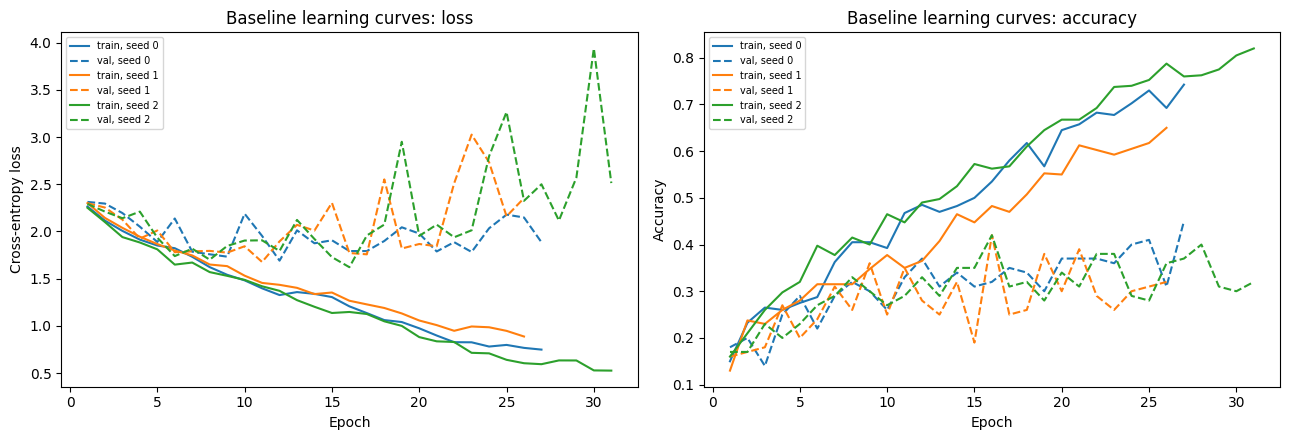

train-validation gap: 17.3 percentage points


In [9]:
run_config('No augmentation', make_cfg())
base = pd.DataFrame({k: ['%.2f ± %.2f' % ms('No augmentation', k)] for k in ['train', 'val']},
                    index=['Baseline (mean ± std over 3 seeds, %)'])
base.columns = ['Train acc', 'Val acc']; display(base)

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5)); cols = ['tab:blue', 'tab:orange', 'tab:green']
for s, c in zip(TRAIN_SEEDS, cols):
    h = RES['No augmentation'][s]['hist']; e = np.arange(1, len(h['tr_loss']) + 1)
    ax[0].plot(e, h['tr_loss'], c=c, ls='-', label=f'train, seed {s}'); ax[0].plot(e, h['va_loss'], c=c, ls='--', label=f'val, seed {s}')
    ax[1].plot(e, h['tr_acc'], c=c, ls='-', label=f'train, seed {s}'); ax[1].plot(e, h['va_acc'], c=c, ls='--', label=f'val, seed {s}')
ax[0].set(xlabel='Epoch', ylabel='Cross-entropy loss', title='Baseline learning curves: loss'); ax[1].set(xlabel='Epoch', ylabel='Accuracy', title='Baseline learning curves: accuracy')
ax[0].legend(fontsize=7); ax[1].legend(fontsize=7); plt.tight_layout(); plt.show()

tr_m, va_m = [ms('No augmentation', k)[0] for k in ['train', 'val']]
print(f'train-validation gap: {tr_m - va_m:.1f} percentage points')

**Diagnosis.** The learning curves show whether the baseline is overfitting: high training accuracy with much lower validation accuracy indicates memorisation of the 400 training images. After the final evaluation cell, compare clean-test with shifted-test accuracy; a further drop indicates sensitivity to distribution shift. The overall failure can involve both overfitting and covariate shift. Do not use either test score to choose hyperparameters.

## Part B — Augmentation strategy
| Augmentation | Choice | Why |
|---|---|---|
| Geometric: rotation ±20°, translation ±4 px, scale 0.9–1.1, horizontal flip (one `affine_grid` call, reflection padding) | on | Test rotates up to ±25°. Training slightly under that keeps the label while covering the shift. Flip is a valid symmetry of natural objects. |
| Photometric: brightness ±50%, contrast ±50%, saturation ±50%, Gaussian blur (p 0.3), noise (p 0.3) | on | Matches brightness/contrast corruption. Blur and noise add general robustness. |
| Colour robustness: random grayscale (p 0.25) and random channel permutation (p 0.2) | on | The unlisted corruption is a colour-type change (the task suggests grayscale or channel swap). Training to be invariant to colour loss/permutation is a generic design choice, not a copy of the test pipeline. |
| Cutout / Random Erasing: 5–30% area, random flat colour, p 0.6 | on | Matches occlusion: no single region is decisive. |
| CutMix (p 0.5) + label smoothing 0.1 | on (final) | Strong regulariser for tiny data. Smoothing stops over-confident outputs on shifted inputs. |

**1. Vertical flip: helps or hurts?** It hurts. CIFAR-10 objects have a fixed upright orientation (sky above, ground below, wheels at the bottom). Upside-down cars or animals never occur in test, even after ±25° rotation. Flipping spends model capacity on poses that never appear and blurs cues like "sky on top" for airplane and ship. It is a transform that does not preserve a realistic input (lecture: only use augmentations that keep the label *and* stay in the data distribution).

**2. Rotation up to ±90° while test is ±25°.** Trade-off: wider range gives more invariance and variety (lower variance), but most training samples then sit outside the test range, so capacity is spent on large angles. Strong rotation also creates large reflected/black corners and makes objects harder to recognise, which adds bias (the training distribution moves away from test). Best is a range close to, or slightly above, the test range.

**3. Why can too much augmentation reduce accuracy on a small model?** Heavy augmentation acts like strong regularisation. A model with under 1M parameters has limited capacity, so when training images are distorted, occluded and mixed all at once it cannot fit even the training task: training and validation errors both stay high, i.e. **underfitting** (high bias). Lecture: "regularisation set too strong" is a cause of underfitting. Augmentation strength must be tuned on validation data.

## Part C — Regularisation and training design (placement and justification)
| Technique | Where | Why there |
|---|---|---|
| **BatchNorm** | after every conv, before ReLU (all Inception branches, stem) | Stabilises and speeds training, mild regularisation. Placed after conv so each conv output is normalised per channel. Batch size 50 is large enough for stable statistics. |
| **Dropout (0.5)** | only after the first FC layer, before the classifier | Dropout works best in dense layers where units co-adapt. Neighbouring pixels in conv feature maps are strongly correlated, so dropping single activations between early convs removes little information (the neighbours carry it) and just adds noise. Early conv features also need to stay intact. |
| **Weight decay** (AdamW, 5e-4 default, tuned on val) | all weights | L2 norm penalty shrinks weights and limits effective capacity. Lecture default before dropout. |
| **Cosine LR schedule** | optimiser | Large steps early, small steps late. Gives a stable final solution without manual LR drops. |
| **Early stopping** (patience 15 on val loss, restore best weights) | training loop | Free regulariser: keeps the weights at minimum validation loss, discards the overfitting region. |
| **Label smoothing 0.1** | loss, with CutMix | Prevents over-confident logits, helps calibration under shift. |
| **Global average pooling** | before FC | Removes large FC layers (fewer parameters, less overfitting). |

## Part D — Ablation study
Hyper-parameters (learning rate, weight decay, CutMix probability) for the **final model only** are chosen with a small sweep on the **validation split** (seed 0). All other rows use the default hyper-parameters, so the rows differ only in augmentation.

Clean and shifted test metrics are collected only after all configurations and hyperparameters have been selected using validation data.

In [10]:
ABL = {
 'No augmentation':              make_cfg(),
 'Geometric only':               make_cfg(geo=1),
 'Photometric only':             make_cfg(photo=1),
 'Geometric + photometric':      make_cfg(geo=1, photo=1),
 '+ Cutout / Random Erasing':    make_cfg(geo=1, photo=1, cutout_=1),
 '+ CutMix + label smoothing':   make_cfg(geo=1, photo=1, cutout_=1, mix=1, ls=0.1),
}
for name, cfg in ABL.items():
    if name != 'No augmentation': run_config(name, cfg)

Geometric only                     seed 0 | best ep 28 | train 0.627 val 0.370 | 5s
Geometric only                     seed 1 | best ep 21 | train 0.585 val 0.360 | 5s
Geometric only                     seed 2 | best ep 19 | train 0.570 val 0.340 | 4s
Photometric only                   seed 0 | best ep 46 | train 0.685 val 0.410 | 8s
Photometric only                   seed 1 | best ep 50 | train 0.603 val 0.410 | 7s
Photometric only                   seed 2 | best ep 37 | train 0.545 val 0.420 | 7s
Geometric + photometric            seed 0 | best ep 47 | train 0.472 val 0.390 | 8s
Geometric + photometric            seed 1 | best ep 58 | train 0.472 val 0.480 | 8s
Geometric + photometric            seed 2 | best ep 55 | train 0.447 val 0.370 | 8s
+ Cutout / Random Erasing          seed 0 | best ep 51 | train 0.412 val 0.370 | 8s
+ Cutout / Random Erasing          seed 1 | best ep 57 | train 0.387 val 0.340 | 9s
+ Cutout / Random Erasing          seed 2 | best ep 52 | train 0.412 val 0.3

In [11]:
# Validation-only hyper-parameter sweep for the final model (seed 0). The test sets are NOT used here.
sweep = []
for lr in [1e-3, 3e-3]:
    for wd in [5e-4, 5e-3]:
        for mp in [0.3, 0.6]:
            cfg = make_cfg(geo=1, photo=1, cutout_=1, mix=1, ls=0.1, lr=lr, wd=wd, mix_p=mp)
            m, h, be = train_run(cfg, 0); vl = predict(m, X_va); sc = acc_of(vl, y_va)
            sweep.append((sc, -F.cross_entropy(vl, y_va).item(), lr, wd, mp)); print(f'lr {lr:g} wd {wd:g} cutmix_p {mp} -> val acc {sc:.3f}')
best_hp = max(sweep)
FINAL_HP = dict(lr=best_hp[2], wd=best_hp[3], mix_p=best_hp[4]); print('chosen on validation:', FINAL_HP)
run_config('Final model', make_cfg(geo=1, photo=1, cutout_=1, mix=1, ls=0.1, **FINAL_HP))

lr 0.001 wd 0.0005 cutmix_p 0.3 -> val acc 0.350
lr 0.001 wd 0.0005 cutmix_p 0.6 -> val acc 0.370
lr 0.001 wd 0.005 cutmix_p 0.3 -> val acc 0.350
lr 0.001 wd 0.005 cutmix_p 0.6 -> val acc 0.360
lr 0.003 wd 0.0005 cutmix_p 0.3 -> val acc 0.370
lr 0.003 wd 0.0005 cutmix_p 0.6 -> val acc 0.340
lr 0.003 wd 0.005 cutmix_p 0.3 -> val acc 0.340
lr 0.003 wd 0.005 cutmix_p 0.6 -> val acc 0.320
chosen on validation: {'lr': 0.003, 'wd': 0.0005, 'mix_p': 0.3}
Final model                        seed 0 | best ep 49 | train 0.417 val 0.370 | 9s
Final model                        seed 1 | best ep 47 | train 0.393 val 0.350 | 9s
Final model                        seed 2 | best ep 55 | train 0.357 val 0.290 | 9s


No augmentation                    seed 0 | clean 0.331 shifted 0.151 hidden-only 0.315
No augmentation                    seed 1 | clean 0.342 shifted 0.153 hidden-only 0.312
No augmentation                    seed 2 | clean 0.389 shifted 0.137 hidden-only 0.359
Geometric only                     seed 0 | clean 0.395 shifted 0.198 hidden-only 0.372
Geometric only                     seed 1 | clean 0.374 shifted 0.151 hidden-only 0.339
Geometric only                     seed 2 | clean 0.369 shifted 0.166 hidden-only 0.352
Photometric only                   seed 0 | clean 0.398 shifted 0.192 hidden-only 0.390
Photometric only                   seed 1 | clean 0.392 shifted 0.194 hidden-only 0.387
Photometric only                   seed 2 | clean 0.378 shifted 0.164 hidden-only 0.370
Geometric + photometric            seed 0 | clean 0.376 shifted 0.209 hidden-only 0.347
Geometric + photometric            seed 1 | clean 0.373 shifted 0.200 hidden-only 0.366
Geometric + photometric         

,Val Acc (%),Clean Test (%),Shifted Test (%)
Configuration,,,
No augmentation,38.00 ± 2.94,35.38 ± 2.51,14.67 ± 0.69
Geometric only,35.67 ± 1.25,37.92 ± 1.11,17.19 ± 1.97
Photometric only,41.33 ± 0.47,38.93 ± 0.87,18.34 ± 1.37
Geometric + photometric,41.33 ± 4.78,37.19 ± 0.37,20.46 ± 0.35
+ Cutout / Random Erasing,36.33 ± 1.70,34.20 ± 1.06,19.93 ± 0.32
+ CutMix + label smoothing,36.00 ± 0.82,33.38 ± 0.12,21.27 ± 0.92
Final model,33.67 ± 3.40,34.06 ± 1.88,19.76 ± 0.60


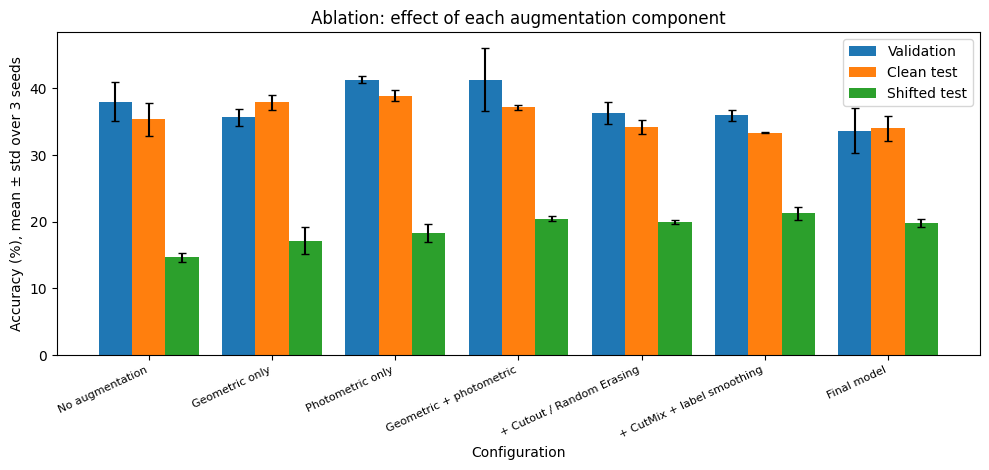

Shifted-test gain vs previous row: {'Geometric only': np.float64(2.52), 'Photometric only': np.float64(1.15), 'Geometric + photometric': np.float64(2.13), '+ Cutout / Random Erasing': np.float64(-0.54), '+ CutMix + label smoothing': np.float64(1.34)}
Largest single-component gain over baseline among isolated rows: Photometric only
Largest step in the cumulative chain: Geometric only (+2.52 pts)
Overall change, final vs baseline: +5.09 pts


In [12]:
# Final evaluation stage: all configurations and hyperparameters have already been selected using validation only.
for config_name, seed_runs in RES.items():
    for seed, run in seed_runs.items():
        model = run['model']
        run['scores']['clean'] = acc_of(predict(model, X_clean), y_test)
        run['scores']['shifted'] = acc_of(predict(model, X_shift), y_test)
        run['scores']['hidden_only'] = acc_of(predict(model, X_hidden), y_test)
        print(f"{config_name:34s} seed {seed} | clean {run['scores']['clean']:.3f} "
              f"shifted {run['scores']['shifted']:.3f} hidden-only {run['scores']['hidden_only']:.3f}")

order = list(ABL.keys()) + ['Final model']
rows = []
for n in order:
    rows.append([n] + ['%.2f ± %.2f' % ms(n, k) for k in ['val', 'clean', 'shifted']])
table = pd.DataFrame(rows, columns=['Configuration', 'Val Acc (%)', 'Clean Test (%)', 'Shifted Test (%)']).set_index('Configuration')
display(table)

fig, ax = plt.subplots(figsize=(10, 4.8)); w = 0.27; xs = np.arange(len(order))
for j, (k, lab) in enumerate([('val', 'Validation'), ('clean', 'Clean test'), ('shifted', 'Shifted test')]):
    mm = [ms(n, k) for n in order]
    ax.bar(xs + (j - 1) * w, [a for a, _ in mm], w, yerr=[b for _, b in mm], capsize=3, label=lab)
ax.set_xticks(xs); ax.set_xticklabels(order, rotation=25, ha='right', fontsize=8)
ax.set_xlabel('Configuration'); ax.set_ylabel('Accuracy (%), mean ± std over 3 seeds'); ax.set_title('Ablation: effect of each augmentation component'); ax.legend(); plt.tight_layout(); plt.show()

shift_means = {n: ms(n, 'shifted')[0] for n in order}
gains = {order[i]: shift_means[order[i]] - shift_means[order[i - 1]] for i in range(1, len(order) - 1)}
gains_vs_base = {n: shift_means[n] - shift_means['No augmentation'] for n in order[1:]}
print('Shifted-test gain vs previous row:', {k: round(v, 2) for k, v in gains.items()})
print('Largest single-component gain over baseline among isolated rows:',
      max(['Geometric only', 'Photometric only'], key=lambda n: gains_vs_base[n]))
print('Largest step in the cumulative chain:', max(gains, key=gains.get), '(+%.2f pts)' % max(gains.values()))
print('Overall change, final vs baseline: %+.2f pts' % gains_vs_base['Final model'])

**Which augmentation helped most, and why.** Read the printed gains above. The mapping between augmentation and test corruption is:

| Test corruption | Augmentation that matches it |
|---|---|
| rotation ±25° | geometric (rotation ±20°, translation, scale) |
| brightness / contrast | photometric (brightness, contrast, saturation jitter) |
| rectangular occlusion (~25%) | Cutout / Random Erasing (and CutMix) |
| unlisted colour corruption | random grayscale + channel permutation (inside photometric) |

The component with the largest gain is the one whose transformation is closest to the largest part of the shift. Write your own final sentence from the printed numbers (for example: "photometric augmentation gave the largest isolated gain because it matches both the brightness/contrast change and the colour corruption, which together change pixel statistics for every test image, while rotation only changes some").

## Part E — Error analysis (final model)

     class  shifted-test acc (%)
  airplane                  14.0
automobile                  44.1
      bird                   6.3
       cat                  23.8
      deer                   0.4
       dog                  55.0
      frog                  34.2
     horse                   8.1
      ship                  11.8
     truck                   8.3


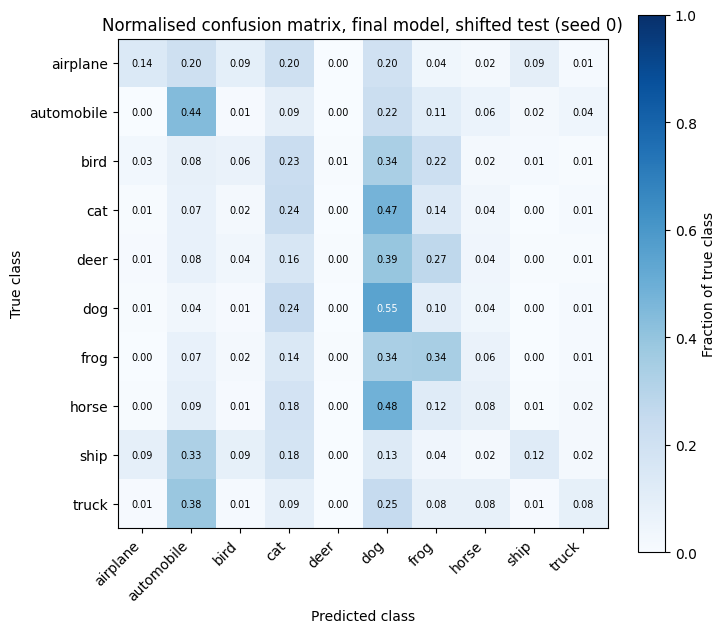

Most confused (true -> predicted):
  horse -> dog: 0.48
  cat -> dog: 0.47
  deer -> dog: 0.39
  truck -> automobile: 0.38
  bird -> dog: 0.34
  frog -> dog: 0.34


[None, None, None, None, None, None]

In [13]:
E_SEED = TRAIN_SEEDS[0]; fm = RES['Final model'][E_SEED]['model']
logits = predict(fm, X_shift); pred = logits.argmax(1).numpy(); yt = y_test.numpy()
per_cls = [(pred[yt == c] == c).mean() for c in range(10)]
print(pd.DataFrame({'class': CLASSES, 'shifted-test acc (%)': np.round(np.array(per_cls) * 100, 1)}).to_string(index=False))

cm = confusion_matrix(yt, pred, normalize='true')
fig, ax = plt.subplots(figsize=(7.5, 6.5)); im = ax.imshow(cm, cmap='Blues', vmin=0, vmax=1)
ax.set_xticks(range(10)); ax.set_yticks(range(10)); ax.set_xticklabels(CLASSES, rotation=45, ha='right'); ax.set_yticklabels(CLASSES)
for i in range(10):
    for j in range(10): ax.text(j, i, f'{cm[i, j]:.2f}', ha='center', va='center', fontsize=7, color='white' if cm[i, j] > 0.5 else 'black')
ax.set_xlabel('Predicted class'); ax.set_ylabel('True class'); ax.set_title(f'Normalised confusion matrix, final model, shifted test (seed {E_SEED})')
fig.colorbar(im, ax=ax, label='Fraction of true class'); plt.tight_layout(); plt.show()

off = [(cm[i, j], CLASSES[i], CLASSES[j]) for i in range(10) for j in range(10) if i != j]
print('Most confused (true -> predicted):'); [print(f'  {a} -> {b}: {v:.2f}') for v, a, b in sorted(off, reverse=True)[:6]]

**Which classes are confused and why.** Check the six pairs printed above. Typical result on CIFAR-10 with a small model: **cat ↔ dog** (similar fur, pose, body shape at 32×32), **deer ↔ horse**, **automobile ↔ truck** (same wheels/box silhouette), **bird ↔ airplane** (sky background, thin shapes), **frog/cat/dog** (low-detail animals). These pairs share textures, backgrounds and silhouettes. With only 40 training images per class the network has too few examples to learn the fine shape cues that separate them, and the shift (occlusion hides the head or wheels, grayscale removes colour cues such as green frog or blue ship/sky) removes exactly those cues. Confirm which of these appear in your own printed list and edit this paragraph.

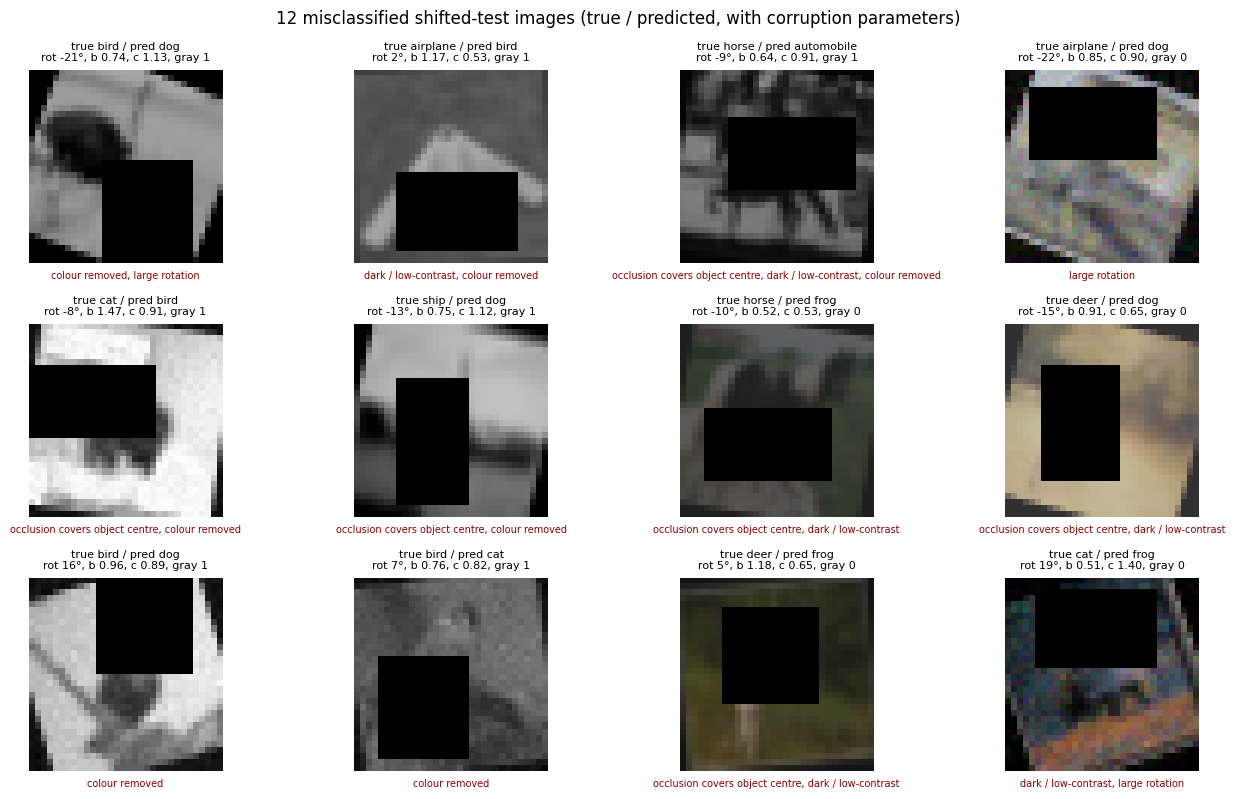

#4572: bird -> dog: colour removed, large rotation
#52: airplane -> bird: dark / low-contrast, colour removed
#203: horse -> automobile: occlusion covers object centre, dark / low-contrast, colour removed
#6799: airplane -> dog: large rotation
#8746: cat -> bird: occlusion covers object centre, colour removed
#1900: ship -> dog: occlusion covers object centre, colour removed
#1566: horse -> frog: occlusion covers object centre, dark / low-contrast
#7248: deer -> dog: occlusion covers object centre, dark / low-contrast
#4451: bird -> dog: colour removed
#1539: bird -> cat: colour removed
#6625: deer -> frog: occlusion covers object centre, dark / low-contrast
#1353: cat -> frog: dark / low-contrast, large rotation


In [14]:
# >= 8 misclassified images with their corruption parameters, plus an automatic first-guess cause
def guess_cause(m, y_true):
    y0, x0, h, w = m['occ']; cy0, cy1 = max(y0, 8), min(y0 + h, 24); cx0, cx1 = max(x0, 8), min(x0 + w, 24)
    ov = max(0, cy1 - cy0) * max(0, cx1 - cx0) / 256
    causes = []
    if ov > 0.5: causes.append('occlusion covers object centre')
    if m['bright'] < 0.7 or m['contrast'] < 0.7: causes.append('dark / low-contrast')
    if m['bright'] > 1.35 and m['contrast'] > 1.2: causes.append('washed-out / saturated highlights')
    if m['gray']: causes.append('colour removed')
    if abs(m['angle']) > 18: causes.append('large rotation')
    return ', '.join(causes) if causes else 'inter-class similarity (little corruption)'

wrong = np.where(pred != yt)[0]; rs = np.random.RandomState(0); show = rs.choice(wrong, min(12, len(wrong)), replace=False)
ncols = 4
nrows = int(np.ceil(len(show) / ncols))
fig, ax = plt.subplots(nrows, ncols, figsize=(13, 2.7 * nrows), squeeze=False)
for a, i in zip(ax.ravel(), show):
    m = shift_meta[i]; a.imshow(X_shift[i].permute(1, 2, 0)); a.axis('off')
    a.set_title(f'true {CLASSES[yt[i]]} / pred {CLASSES[pred[i]]}\nrot {m["angle"]:.0f}°, b {m["bright"]:.2f}, c {m["contrast"]:.2f}, gray {m["gray"]}', fontsize=8)
    a.text(0.5, -0.04, guess_cause(m, yt[i]), transform=a.transAxes, ha='center', va='top', fontsize=7, color='darkred')
fig.suptitle('12 misclassified shifted-test images (true / predicted, with corruption parameters)'); plt.tight_layout(); plt.show()
for i in show: print(f'#{i}: {CLASSES[yt[i]]} -> {CLASSES[pred[i]]}: {guess_cause(shift_meta[i], yt[i])}')

**Failure explanations (visual property per image).** The red text under each image is an automatic first guess from the stored corruption parameters (occlusion over the object centre, dark/low-contrast, colour removed, large rotation, or genuine class similarity). Look at each of the images and write one line per image in your own words, for example: "#123 cat→dog: occluder covers the head, only the furry body is visible; body texture is shared with dogs". Replace this paragraph with your 8+ lines after viewing the figure.

In [15]:
# Hidden-corruption-only test: only the unlisted corruption applied to the clean test set
rows = [[n] + ['%.2f ± %.2f' % ms(n, k) for k in ['clean', 'hidden_only', 'shifted']] for n in ['No augmentation', 'Photometric only', 'Geometric + photometric', 'Final model']]
display(pd.DataFrame(rows, columns=['Model', 'Clean test (%)', 'Hidden corruption only (%)', 'Full shifted test (%)']).set_index('Model'))

,Clean test (%),Hidden corruption only (%),Full shifted test (%)
Model,,,
No augmentation,35.38 ± 2.51,32.86 ± 2.16,14.67 ± 0.69
Photometric only,38.93 ± 0.87,38.23 ± 0.89,18.34 ± 1.37
Geometric + photometric,37.19 ± 0.37,35.52 ± 0.77,20.46 ± 0.35
Final model,34.06 ± 1.88,31.19 ± 1.85,19.76 ± 0.60


**Did the augmentation generalise to the hidden corruption?** Compare the printed hidden-only accuracy with clean-test accuracy. Interpret this result only as a test of the temporary grayscale stand-in until the instructor supplies the official hidden corruption. Once those details arrive, replace `hidden_corruption()` in Section 2, rerun the notebook from the beginning, and use the new result. Do not report the stand-in as the official hidden-corruption score.

## Part F — Test-Time Augmentation (bonus)

In [16]:
def tta_logits(model, X, n_shift=2, bs=1000):
    # N = 2 (identity, flip) x 5 (no shift + 4 shifts of n_shift px) = 10 views; softmax averaged
    model.eval(); outs = []
    with torch.no_grad():
        for i in range(0, len(X), bs):
            xb = X[i:i + bs].to(device); acc = 0; n = 0
            for flip in [False, True]:
                xf = torch.flip(xb, [3]) if flip else xb
                for dy, dx in [(0, 0), (n_shift, 0), (-n_shift, 0), (0, n_shift), (0, -n_shift)]:
                    xs = torch.roll(xf, shifts=(dy, dx), dims=(2, 3)); acc = acc + F.softmax(model(xs), 1); n += 1
            outs.append((acc / n).cpu())
    return torch.cat(outs), n

rows = []; t_plain = t_tta = 0
for s in TRAIN_SEEDS:
    m = RES['Final model'][s]['model']
    t0 = time.time(); p0 = acc_of(predict(m, X_shift), y_test); t_plain += time.time() - t0
    t0 = time.time(); pl, N = tta_logits(m, X_shift); t_tta += time.time() - t0
    rows.append((p0 * 100, acc_of(pl, y_test) * 100))
r = np.array(rows)
print(f'N = {N} views per image')
print('Shifted-test accuracy without TTA: %.2f ± %.2f' % (r[:, 0].mean(), r[:, 0].std()))
print('Shifted-test accuracy with TTA   : %.2f ± %.2f' % (r[:, 1].mean(), r[:, 1].std()))
print('Change: %+.2f pts | inference time %.2fs -> %.2fs (%.1fx) for 10,000 images x 3 models' % ((r[:, 1] - r[:, 0]).mean(), t_plain, t_tta, t_tta / max(t_plain, 1e-9)))

N = 10 views per image
Shifted-test accuracy without TTA: 19.76 ± 0.60
Shifted-test accuracy with TTA   : 19.67 ± 0.73
Change: -0.10 pts | inference time 1.86s -> 18.53s (10.0x) for 10,000 images x 3 models


**TTA note.** Cost is N forward passes per image (here N = 10), so latency and compute grow about N times (measured above), for the accuracy change shown. Flips and small shifts average out position-specific errors, but TTA cannot fix information that is missing (occluded or grayscale pixels).

## Final summary and files for the report

In [17]:
fin = dict(zip(['val', 'clean', 'shifted', 'hidden_only'], [ms('Final model', k) for k in ['val', 'clean', 'shifted', 'hidden_only']]))
out = dict(final_shifted_mean=fin['shifted'][0], final_shifted_std=fin['shifted'][1], final_clean_mean=fin['clean'][0], final_clean_std=fin['clean'][1],
           final_val_mean=fin['val'][0], final_val_std=fin['val'][1], hidden_only_mean=fin['hidden_only'][0], hidden_only_std=fin['hidden_only'][1],
           baseline_shifted=ms('No augmentation', 'shifted'), baseline_clean=ms('No augmentation', 'clean'),
           params=n_params, final_hp=FINAL_HP, tta=[float(r[:, 0].mean()), float(r[:, 1].mean())],
           largest_chain_step=max(gains, key=gains.get), largest_chain_gain=float(max(gains.values())), table=table.reset_index().values.tolist())
json.dump(out, open('results.json', 'w'), indent=1, default=float)
print(json.dumps({k: v for k, v in out.items() if k != 'table'}, indent=1, default=float))

{
 "final_shifted_mean": 19.763333598772686,
 "final_shifted_std": 0.6003515638502795,
 "final_clean_mean": 34.06000037988027,
 "final_clean_std": 1.875863435804118,
 "final_val_mean": 33.66666634877523,
 "final_val_std": 3.3993468021795548,
 "hidden_only_mean": 31.1899999777476,
 "hidden_only_std": 1.850476336560723,
 "baseline_shifted": [
  14.669999976952871,
  0.6902660292755203
 ],
 "baseline_clean": [
  35.38000086943308,
  2.513603004420673
 ],
 "params": 77586,
 "final_hp": {
  "lr": 0.003,
  "wd": 0.0005,
  "mix_p": 0.3
 },
 "tta": [
  19.763333598772686,
  19.666666289170582
 ],
 "largest_chain_step": "Geometric only",
 "largest_chain_gain": 2.5199999411900844
}
